# Research extension Q6: 200 state objectives and sampled lexicase selection

The requested change creates **four objective families times 50 states = 200 objectives**, not 50 objectives total. We retain one shared ZIP-scoring network and one national allocation budget. The network still returns one score per ZIP; the evaluator now returns a 50-by-4 fitness matrix. No state quotas or 50 separate networks are introduced.

This continues our Q4/Q5 methodological reconstruction using NEAT genome crossover and mutation operators, not a verified numerical replication of EVA. The reconstructed evolutionary loop has no NEAT species allocation. Paper 2 motivates the scoring, objective and evolutionary framework; the state decomposition and experiments here are our extension. We retain Q5's capacity-aware raw-score softmax at temperature $T=0.01$.

## 1. All 50 states and an explicit reference

The supplied CSV contains 10,476 eligible ZIPs in the 50 states. Exclude the District of Columbia and the Puerto Rico municipal labels. The original CSV is not exhaustive coverage of every ZIP in each state.

Q4's EIA-based preparation omitted Alabama because its baseline value was missing. Reusing that preparation would silently create only 196 objectives. We instead include Alabama and define a capacity-proportional reference allocation:

$$
b_i=N\frac{u_i}{\sum_j u_j},\qquad N=2{,}000{,}000,\qquad u_i=\lfloor\mathrm{count\_qualified}_i\rfloor.
$$

This is a fractional benchmark, not a sampled deployment or a forecast of adoption. It has total $N$ and satisfies $0\le b_i\le u_i$. Every state has positive reference carbon, energy and equity in these data. We do not impute an EIA value or add arbitrary smoothing constants to denominators. The state list is explicit in `states.json`; no EIA numerical values are used in this experiment.

All methods in this question use the same all-50-state data, input normalization, placement policy, reference and computational budget. Their ratios must not be compared numerically with Q5's differently defined baseline. Toolkit installation-unit and energy/carbon indicator conventions remain as in Q4, so these results are not engineering forecasts.

## 2. Define the state objectives

Let $Z_s$ be the ZIPs in state $s$, $a_i$ the additional allocation and $I_i$ the existing installations. With per-unit toolkit indicators $c_i$ and $e_i$, define

$$
C_s(a)=\sum_{i\in Z_s}a_i c_i,\qquad E_s(a)=\sum_{i\in Z_s}a_i e_i.
$$

For income and Black-population-proportion equity, partition ZIPs using the respective **within-state median**. ZIPs at the median enter the high group. Define $H_{s,k}$ and $L_{s,k}$ for demographic family $k$, and

$$
Q_{s,k}(a)=1-\frac{\left|\sum_{i\in H_{s,k}}(I_i+a_i)-\sum_{i\in L_{s,k}}(I_i+a_i)\right|}{\sum_{i\in Z_s}(I_i+a_i)}.
$$

Within-state medians make these measures local distributional comparisons. They are a stated modeling choice: a ZIP can be high relative to its state and low relative to the country. Consequently, these are not a partition of the original national demographic cohorts. Equal counts across two ZIP groups are a demographic proxy, not a guarantee of household-level fairness.

Both groups exist and total existing installations are positive in every state in these data. A state receiving no new units has zero new carbon and energy, while its equity remains its existing-installation equity. It is not assigned perfect equity or a missing value.

Normalize each objective against the same state's reference:

$$
R_{s,k}(a)=\frac{F_{s,k}(a)}{F_{s,k}(b)}.
$$

The 200-vector uses state-major order, with families carbon, energy, racial equity and income equity. For $s=0,\ldots,49$ and $k=0,\ldots,3$, case index $j=4s+k$.

## 3. Sample 40 cases per generation

At each generation, uniformly sample 10 distinct states without replacement. Include all four families for each selected state. This produces 40 cases and prevents a generation's subset from containing only energy or only equity cases. It also makes the state inclusion probability exactly $10/50=0.2$. The subset is shared by all candidates and all nine survivor-selection events in that generation. Each event shuffles its case order independently.

The subset changes between generations. Independent sampling does not guarantee coverage: a particular state is never sampled over $G$ generations with probability $0.8^G$. After 30 generations the expected number of unsampled states is $50(0.8)^{30}\approx0.0619$. Actual coverage must be logged rather than presumed.

## 4. Semi-dynamic epsilon-lexicase survival

Use continuous-valued epsilon-lexicase instead of exact-best filtering. For every case $j$, calculate one tolerance from the full generation's population:

$$
\epsilon_j=\operatorname{median}_g\left|R_{g,j}-\operatorname{median}_h R_{h,j}\right|.
$$

For each survivor slot, start with all candidates not already selected and shuffle the sampled cases. For case $j$ and current pool $P$, retain

$$
P\leftarrow\left\{g\in P:R_{g,j}\ge\max_{h\in P}R_{h,j}-\epsilon_j\right\}.
$$

Stop when one remains or the cases are exhausted, then choose uniformly among remaining candidates. Repeat to obtain nine distinct survivors. Removing already selected winners is our without-replacement survivor variant; it preserves Q4's pool of distinct parents for crossover. Standard lexicase parent sampling is commonly with replacement, so its selection guarantees should not be transferred unchanged to this variant.

A case tied across the population leaves the pool unchanged. If MAD is zero but candidates differ, filtering uses the exact best score. No arbitrary ordering is used to discard identical candidates.

Positive affine rescaling of an individual case rescales its MAD by the same factor and leaves its filtering decisions unchanged, apart from numerical precision. Thus carbon's numerical units do not automatically dominate the selector. Normalization matters for scalar model ranking, crossover fitness and interpretation, rather than being necessary to make case-by-case filtering unit invariant.

## 5. Keep scalar preferences visible

Lexicase survival uses the case vector, but the reconstructed EVA loop still needs scalar decisions for checkpoint choice, the retained elite and the fitter parent in NEAT crossover. For the state methods, begin with

$$
S_{\mathrm{CPR}}=\frac{4}{200}\sum_{s,k}R_{s,k}.
$$

This equals the mean of 50 state CPRs and equals four at the reference. It weights states equally, not by population, capacity or national energy contribution. We choose the highest-scoring member of the nine selected survivors as the generation's elite, and return the best selected checkpoint across generations. The national control instead uses the sum of its four national ratios.

Initial diagnostics showed that a few extremely large state ratios can dominate this scalar score even when most states receive little benefit. We therefore test a separate exploratory variant:

$$
S_{\log}=\frac{4}{200\log 2}\sum_{s,k}\log(1+R_{s,k}).
$$

Its marginal reward is proportional to $1/(1+R)$, so increasing an already large ratio receives less reward. It is finite at zero and still equals four at the reference. The log is applied to the estimated mean ratios; lexicase still filters on the original case ratios and MAD tolerances. This change affects checkpoint ranking, elitism and crossover fitness, not only reporting. It is not a proof that all states improve, nor a max-min fairness constraint.

## 6. Experimental controls and evaluation

Compare five methods:

| Method | Survival cases | Scalar checkpoint/crossover score |
|---|---|---|
| National 4 | Four national objectives, using national medians | National CPR |
| State means 4 | Four equal-state averages of state ratios | State CPR |
| State 200 | All 200 state-family cases | State CPR |
| State subset 40 | Four cases for each of 10 sampled states | State CPR |
| Subset 40 + log score | The same sampled-case design | Logarithmic state score |

The state-means control separates averaging away state-specific performance from the state decomposition itself. Comparing State 200 and State subset 40 isolates case subsampling. Comparing the two subset methods isolates the scalar-score change. National versus state methods also differ in demographic thresholds and scalar geographic preferences, so that comparison is not a one-factor causal test.

All runs use 30 networks, 30 generations, nine distinct survivors, one selected elite and 29 offspring from distinct shuffled survivor pairs. This is a fixed-budget experiment without Q5's outer selectivity-tuning loop. Each candidate is evaluated on placement seeds 10, 11, 12 and 13, averaging realized objective values before normalization. State equity has a random state-specific denominator, so we do not reuse Q5's fixed-denominator Jensen argument.

Use evolutionary seeds 0 through 4, with seed 0 as the primary illustration. Initial diagnostics used placement seeds 20000 through 20099 and motivated the log-score variant. Final tables evaluate every method again using fresh placement seeds **40000 through 40099**, which were not used for training, checkpoint selection or the earlier diagnostics. These are held-out deployment draws on the same dataset, not held-out states or evidence of geographic generalization. The additional variant is exploratory rather than a preregistered confirmatory result.

First average 100 deployment draws for each learned network, then summarize those five network means. Between-training-seed standard deviations are stored separately from deployment variation. State success counts refer to all four held-out mean ratios reaching one, not to a statistical significance test or a guarantee for every deployment.

We evaluate all 200 scores for checkpointing and diagnostics, even when survival uses only 40. Thus this implementation does not claim the simulation-cost savings sometimes associated with down-sampled lexicase. The expensive global softmax allocation is still performed over all eligible ZIPs.


Install dependencies once with `pip install -r requirements.txt`, then run from the extracted folder. Git and internet are needed to fetch the pinned source on first use. The default `retrain = False` loads the supplied locally generated models and reruns final evaluation; set it to `True` to retrain all 25 models. All new state-objective, selection and training functions are expanded below.

In [1]:
import sys
import subprocess
import json
import pickle
from pathlib import Path

root = Path.cwd()
source = root / "SunSight_Q3"
pin = "99588d1696c980075a19abf087c669ae5aa22e4e"
if not source.exists():
    subprocess.run(["git", "clone", "--filter=blob:none", "--sparse", "https://github.com/coopersigrist/SunSight.git", str(source)], check=True)
    subprocess.run(["git", "-C", str(source), "checkout", pin], check=True)
    subprocess.run(["git", "-C", str(source), "sparse-checkout", "add", "Simulation", "Models/Neat"], check=True)
if subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip() != pin:
    raise RuntimeError("The source must be at the pinned commit.")
sys.path.insert(0, str(source))
sys.path.insert(0, str(root))


In [2]:
import copy
import itertools
import random
from pathlib import Path

import neat
import numpy as np
import pandas as pd

from q4_eva import FIELDS, OBJECTIVES, network_scores
from q5_softmax import softmax_allocation


def prepare_states(raw, state_names, n=2_000_000):
    states = sorted(state_names)
    if len(states) != 50 or len(set(states)) != 50:
        raise ValueError("Exactly 50 distinct state names are required.")
    data = raw.loc[raw["state_name"].isin(states)].sort_values("region_name").reset_index(drop=True).copy()
    required = FIELDS + ["count_qualified", "existing_installs_count"]
    if set(data["state_name"]) != set(states) or data["region_name"].duplicated().any():
        raise ValueError("Every state needs data and ZIP identifiers must be unique.")
    if not np.isfinite(data[required].to_numpy()).all() or not data["count_qualified"].gt(0).all():
        raise ValueError("Required attributes must be finite and capacities positive.")
    capacity = np.floor(data["count_qualified"]).to_numpy(dtype=np.int64)
    if n <= 0 or n > capacity.sum():
        raise ValueError("The installation budget must be positive and feasible.")
    groups = pd.Categorical(data["state_name"], categories=states).codes
    if (data["existing_installs_count"] < 0).any() or (np.bincount(groups, weights=data["existing_installs_count"], minlength=50) <= 0).any():
        raise ValueError("Every state needs positive existing installations to define no-new-allocation equity.")
    signs = []
    national_signs = []
    for field in ["black_prop", "Median_income"]:
        medians = data.groupby("state_name")[field].transform("median")
        high = data[field].ge(medians).to_numpy()
        if any(high[groups == s].all() or not high[groups == s].any() for s in range(50)):
            raise ValueError("Both demographic groups must be present in every state.")
        signs.append(np.where(high, 1.0, -1.0))
        national_signs.append(np.where(data[field].ge(data[field].median()), 1.0, -1.0))
    values = data[FIELDS].to_numpy()
    spread = np.ptp(values, axis=0)
    inputs = np.column_stack([np.ones(len(data)), (values - values.min(axis=0)) / np.where(spread > 0, spread, 1)])
    experiment = {"data": data, "states": states, "groups": groups, "capacity": capacity, "inputs": inputs, "existing": data["existing_installs_count"].to_numpy(), "carbon": data[FIELDS[1]].to_numpy(), "energy": data[FIELDS[2]].to_numpy(), "signs": np.array(signs), "national_signs": np.array(national_signs), "n": int(n)}
    reference = n * capacity / capacity.sum()
    experiment["reference"] = reference
    experiment["state_reference"] = state_values(experiment, reference)
    experiment["national_reference"] = national_values(experiment, reference)
    if (experiment["state_reference"] <= 0).any() or (experiment["national_reference"] <= 0).any():
        raise ValueError("Reference objectives must be positive; no arbitrary denominator smoothing is used.")
    return experiment


def state_values(experiment, allocation):
    groups = experiment["groups"]
    installed = experiment["existing"] + allocation
    totals = np.bincount(groups, weights=installed, minlength=50)
    carbon = np.bincount(groups, weights=allocation * experiment["carbon"], minlength=50)
    energy = np.bincount(groups, weights=allocation * experiment["energy"], minlength=50)
    equity = [1 - np.abs(np.bincount(groups, weights=installed * sign, minlength=50)) / totals for sign in experiment["signs"]]
    return np.column_stack([carbon, energy, *equity])


def national_values(experiment, allocation):
    installed = experiment["existing"] + allocation
    equity = 1 - np.abs(experiment["national_signs"] @ installed) / installed.sum()
    return np.array([allocation @ experiment["carbon"], allocation @ experiment["energy"], *equity])


def candidate_fitness(experiment, network, temperature, placement_seeds):
    scores = network_scores(network, experiment["inputs"])
    local = np.zeros((50, 4))
    national = np.zeros(4)
    for seed in placement_seeds:
        allocation = softmax_allocation(scores, experiment["capacity"], experiment["n"], temperature, np.random.default_rng(seed))
        local += state_values(experiment, allocation)
        national += national_values(experiment, allocation)
    return local / len(placement_seeds) / experiment["state_reference"], national / len(placement_seeds) / experiment["national_reference"]


def sample_cases(rng, states_per_generation=10):
    if not isinstance(states_per_generation, (int, np.integer)) or not 1 <= states_per_generation <= 50:
        raise ValueError("Sample between 1 and 50 states.")
    states = rng.choice(50, size=states_per_generation, replace=False)
    return (4 * states[:, None] + np.arange(4)).ravel()


def epsilon_survivors(fitness, cases, count, rng):
    fitness = np.asarray(fitness, dtype=float)
    cases = np.asarray(cases, dtype=int)
    if fitness.ndim != 2 or not np.isfinite(fitness).all() or not 1 <= count <= len(fitness):
        raise ValueError("A finite candidate-by-objective matrix and feasible survivor count are required.")
    if len(cases) == 0 or len(np.unique(cases)) != len(cases) or (cases < 0).any() or (cases >= fitness.shape[1]).any():
        raise ValueError("Cases must be distinct valid objective indices.")
    median = np.median(fitness, axis=0)
    epsilon = np.median(np.abs(fitness - median), axis=0)
    available = np.arange(len(fitness))
    selected = []
    events = []
    for slot in range(count):
        pool = available.copy()
        order = rng.permutation(cases)
        for position, case in enumerate(order):
            if len(pool) == 1:
                break
            before = len(pool)
            best = fitness[pool, case].max()
            pool = pool[fitness[pool, case] >= best - epsilon[case]]
            events.append([slot, position, int(case), before, len(pool)])
        winner = int(rng.choice(pool))
        selected.append(winner)
        available = available[available != winner]
    return np.array(selected), events


def train_state_eva(experiment, config_path, seed, mode="state_subset", generations=30, temperature=0.01, placement_seeds=(10, 11, 12, 13), states_per_generation=10, checkpoint="cpr"):
    if checkpoint not in ["cpr", "log"]:
        raise ValueError("Checkpoint scoring must be cpr or log.")
    if mode not in ["national", "state_mean", "state_all", "state_subset"]:
        raise ValueError("Unknown selection mode.")
    random.seed(seed)
    config = neat.Config(neat.DefaultGenome, neat.DefaultReproduction, neat.DefaultSpeciesSet, neat.DefaultStagnation, str(config_path))
    if len(config.genome_config.input_keys) != experiment["inputs"].shape[1]:
        raise ValueError("The network input size does not match the normalized data.")
    selection_rng = np.random.default_rng(100_000 + seed)
    subset_rng = np.random.default_rng(200_000 + seed)
    population = []
    next_id = 0
    for _ in range(30):
        genome = neat.DefaultGenome(next_id)
        next_id += 1
        genome.configure_new(config.genome_config)
        population.append(genome)
    best_genome = None
    best_score = -np.inf
    history = []
    subset_log = []
    event_log = []
    for generation in range(generations):
        local_fitness = []
        national_fitness = []
        for genome in population:
            network = neat.nn.FeedForwardNetwork.create(genome, config)
            local, national = candidate_fitness(experiment, network, temperature, placement_seeds)
            local_fitness.append(local.ravel())
            national_fitness.append(national)
        local_fitness = np.array(local_fitness)
        national_fitness = np.array(national_fitness)
        fitness = national_fitness if mode == "national" else local_fitness.reshape(30, 50, 4).mean(axis=1) if mode == "state_mean" else local_fitness
        cpr = fitness.sum(axis=1) if mode == "national" else fitness.mean(axis=1) * 4
        if checkpoint == "log":
            cpr = 4 * np.log1p(fitness).mean(axis=1) / np.log(2)
        for genome, score in zip(population, cpr):
            genome.fitness = float(score)
        cases = np.arange(4) if mode in ["national", "state_mean"] else np.arange(200) if mode == "state_all" else sample_cases(subset_rng, states_per_generation)
        survivors, events = epsilon_survivors(fitness, cases, 9, selection_rng)
        for case in cases:
            subset_log.append([generation, int(case)])
        event_log.extend([[generation, *event] for event in events])
        winner = int(survivors[np.argmax(cpr[survivors])])
        history.append([generation, float(cpr[winner]), *national_fitness[winner], *local_fitness[winner].reshape(50, 4).mean(axis=0)])
        if cpr[winner] > best_score:
            best_score = float(cpr[winner])
            best_genome = copy.deepcopy(population[winner])
        if generation + 1 < generations:
            selected = [population[i] for i in survivors]
            pairs = list(itertools.combinations(selected, 2))
            random.shuffle(pairs)
            new_population = [copy.deepcopy(population[winner])]
            for first, second in pairs[:29]:
                child = neat.DefaultGenome(next_id)
                next_id += 1
                child.configure_crossover(first, second, config.genome_config)
                child.mutate(config.genome_config)
                new_population.append(child)
            population = new_population
    history = pd.DataFrame(history, columns=["Generation", "Training checkpoint score", *["National " + x for x in OBJECTIVES], *["State mean " + x for x in OBJECTIVES]])
    subsets = pd.DataFrame(subset_log, columns=["Generation", "Case"])
    events = pd.DataFrame(event_log, columns=["Generation", "Slot", "Position", "Case", "Before", "After"])
    return neat.nn.FeedForwardNetwork.create(best_genome, config), history, subsets, events


def evaluate_state_model(experiment, network, temperature=0.01, deployment_seeds=range(20_000, 20_100)):
    scores = network_scores(network, experiment["inputs"])
    rows = []
    state_rows = []
    for seed in deployment_seeds:
        allocation = softmax_allocation(scores, experiment["capacity"], experiment["n"], temperature, np.random.default_rng(seed))
        local = state_values(experiment, allocation) / experiment["state_reference"]
        national = national_values(experiment, allocation) / experiment["national_reference"]
        allocated = np.bincount(experiment["groups"], weights=allocation, minlength=50)
        rows.append([seed, *national, *local.mean(axis=0), int((allocated > 0).sum()), int((allocation > 0).sum())])
        state_rows.extend([[seed, state, allocated[s], *local[s]] for s, state in enumerate(experiment["states"])])
    columns = ["Deployment seed", *["National " + x for x in OBJECTIVES], *["State mean " + x for x in OBJECTIVES], "States allocated", "ZIPs allocated"]
    return pd.DataFrame(rows, columns=columns), pd.DataFrame(state_rows, columns=["Deployment seed", "State", "Allocation", *OBJECTIVES])


In [3]:
state_names = json.loads((root / "states.json").read_text())
experiment = prepare_states(pd.read_csv(root / "data_by_zip.csv"), state_names)
config_path = source / "Models" / "Neat" / "neat-config"
print("ZIPs:", len(experiment["data"]), "States:", len(experiment["states"]), "Objectives:", experiment["state_reference"].size)


ZIPs: 10476 States: 50 Objectives: 200


In [4]:
retrain = False
models = {}
for label in ["national", "state_mean", "state_all", "state_subset", "state_subset_log"]:
    for seed in range(5):
        path = root / f"{label}_seed_{seed}.pkl"
        if retrain:
            mode = "state_subset" if label == "state_subset_log" else label
            checkpoint = "log" if label == "state_subset_log" else "cpr"
            network, history, subsets, events = train_state_eva(experiment, config_path, seed, mode, checkpoint=checkpoint)
            path.write_bytes(pickle.dumps(network))
            history.to_csv(root / f"{label}_history_{seed}.csv", index=False)
            subsets.to_csv(root / f"{label}_subsets_{seed}.csv", index=False)
            events.to_csv(root / f"{label}_events_{seed}.csv", index=False)
        else:
            network = pickle.loads(path.read_bytes())
        models[(label, seed)] = network


In [5]:
for (label, seed), network in models.items():
    national, local = evaluate_state_model(experiment, network, deployment_seeds=range(40_000, 40_100))
    national.to_csv(root / f"{label}_national_test_{seed}.csv", index=False)
    local.to_csv(root / f"{label}_state_test_{seed}.csv", index=False)


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from q4_eva import OBJECTIVES


def summarize_results(root):
    root = Path(root)
    endpoint = []
    state = []
    coverage = []
    for mode in ["national", "state_mean", "state_all", "state_subset", "state_subset_log"]:
        for seed in range(5):
            national = pd.read_csv(root / f"{mode}_national_test_{seed}.csv")
            local = pd.read_csv(root / f"{mode}_state_test_{seed}.csv")
            average = local.groupby("State")[OBJECTIVES].mean()
            metrics = national.drop(columns="Deployment seed").mean().to_dict()
            metrics.update({"Mode": mode, "Evolution seed": seed})
            for objective in OBJECTIVES:
                metrics["State median " + objective] = average[objective].median()
                metrics["State minimum " + objective] = average[objective].min()
                metrics["State Q10 " + objective] = average[objective].quantile(0.1)
                metrics["States below reference " + objective] = int((average[objective] < 1).sum())
            metrics["States meeting all four in held-out means"] = int(average.ge(1).all(axis=1).sum())
            metrics["State CPR"] = average.to_numpy().mean() * 4
            metrics["National CPR"] = sum(metrics["National " + name] for name in OBJECTIVES)
            endpoint.append(metrics)
            average["Mode"] = mode
            average["Evolution seed"] = seed
            state.append(average.reset_index())
            if mode in ["state_all", "state_subset", "state_subset_log"]:
                subsets = pd.read_csv(root / f"{mode}_subsets_{seed}.csv")
                events = pd.read_csv(root / f"{mode}_events_{seed}.csv")
                counts = subsets.assign(StateIndex=subsets["Case"] // 4).groupby("StateIndex").size().reindex(range(50), fill_value=0) / 4
                effective = events.loc[events["After"] < events["Before"]].assign(StateIndex=lambda x: x["Case"] // 4).groupby("StateIndex").size().reindex(range(50), fill_value=0)
                depths = events.groupby(["Generation", "Slot"]).size()
                coverage.append({"Mode": mode, "Evolution seed": seed, "States ever sampled": int((counts > 0).sum()), "Minimum sampled generations": counts.min(), "Maximum sampled generations": counts.max(), "Mean cases examined per slot": depths.mean(), "Fraction examined cases reducing pool": (events["After"] < events["Before"]).mean(), "States ever reducing a pool": int((effective > 0).sum())})
    endpoint = pd.DataFrame(endpoint)
    state = pd.concat(state, ignore_index=True)
    coverage = pd.DataFrame(coverage)
    endpoint.to_csv(root / "per_run_summary.csv", index=False)
    state.to_csv(root / "state_heldout_means.csv", index=False)
    coverage.to_csv(root / "selection_diagnostics.csv", index=False)
    metrics = endpoint.select_dtypes(include=np.number).columns.drop("Evolution seed")
    endpoint.groupby("Mode")[metrics].mean().to_csv(root / "five_seed_means.csv")
    endpoint.groupby("Mode")[metrics].std().to_csv(root / "five_seed_sd.csv")
    return endpoint, state, coverage


def plot_results(root, endpoint, state):
    root = Path(root)
    labels = {"national": "National 4", "state_mean": "State means 4", "state_all": "State 200", "state_subset": "State subset 40", "state_subset_log": "Subset 40 + log score"}
    colors = dict(zip(labels, ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax, objective in zip(axes, ["Carbon", "Energy"]):
        for mode in labels:
            points = endpoint.loc[endpoint["Mode"] == mode]
            ax.scatter(points["National " + objective], points["State mean " + objective], label=labels[mode], color=colors[mode], s=35)
        ax.axhline(1, color="gray", linestyle=":")
        ax.axvline(1, color="gray", linestyle=":")
        ax.set(title=objective, xlabel="National ratio to capacity reference", ylabel="Unweighted mean of 50 state ratios")
        ax.grid(alpha=0.15)
    axes[0].legend(fontsize=8)
    fig.suptitle("National performance and the average state can move in opposite directions | five training seeds")
    fig.savefig(root / "national_vs_state.png", dpi=180)
    plt.show()
    plt.close(fig)
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for ax, objective in zip(axes.flat, OBJECTIVES):
        for mode in labels:
            values = state.loc[(state["Mode"] == mode) & (state["Evolution seed"] == 0), objective].sort_values().to_numpy()
            ax.plot(np.arange(1, 51), values, label=labels[mode], color=colors[mode])
        ax.axhline(1, color="gray", linestyle=":")
        ax.set(title=objective, xlabel="State rank within each policy, worst to best", ylabel="Held-out mean state ratio")
        ax.grid(alpha=0.15)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle("Primary training seed 0 | each curve sorts its own 50 states | 100 deployment draws")
    fig.savefig(root / "state_distribution.png", dpi=180)
    plt.show()
    plt.close(fig)


                  National Carbon  National Energy  National Racial equity  National Income equity  State mean Carbon  State mean Energy  State mean Racial equity  State mean Income equity  States meeting all four in held-out means
Mode                                                                                                                                                                                                                                   
national                   1.4763           1.0199                  0.9807                  1.0986             1.5372             1.4289                    0.8514                    0.8299                                        0.0
state_all                  0.5493           0.8632                  0.5671                  0.8532             2.1351             2.1742                    1.0132                    0.9280                                        6.0
state_mean                 0.5615           0.8807                  0.44

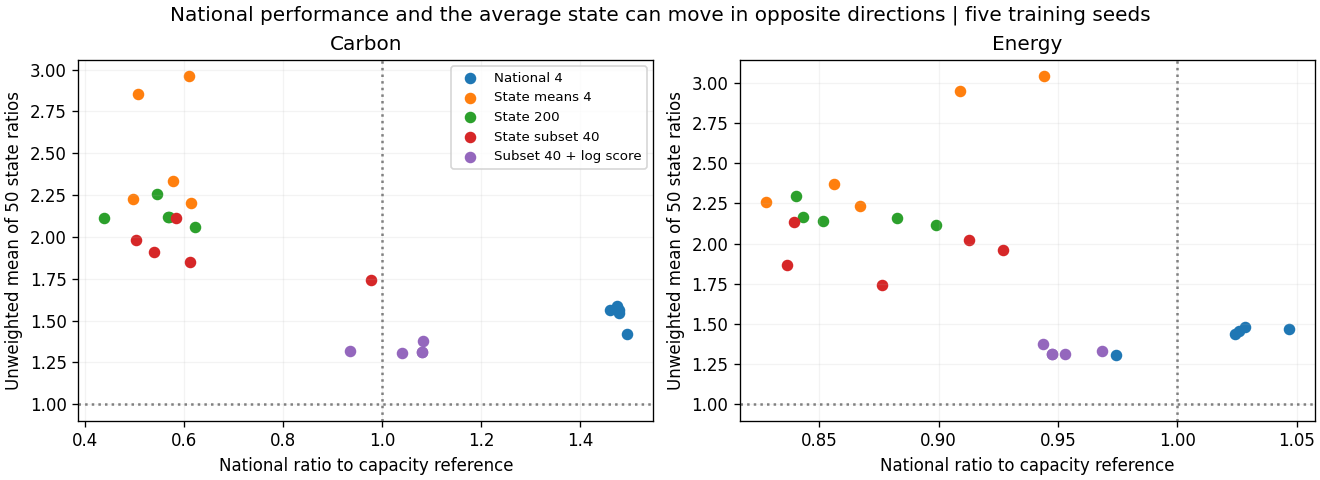

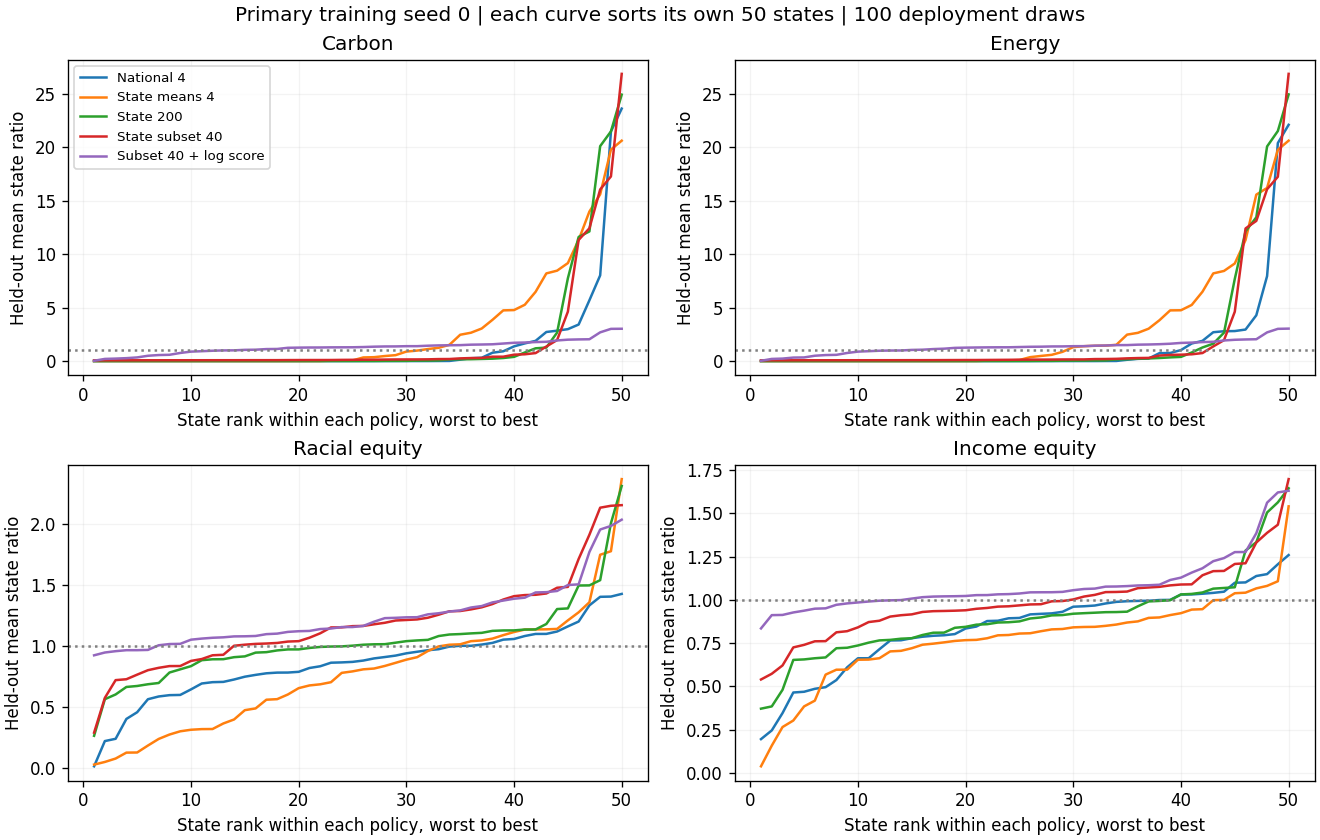

In [7]:
endpoint, state, coverage = summarize_results(root)
columns = ["National " + name for name in OBJECTIVES] + ["State mean " + name for name in OBJECTIVES] + ["States meeting all four in held-out means"]
print(endpoint.groupby("Mode")[columns].mean().round(4).to_string())
print(endpoint.groupby("Mode")[columns].std().round(4).to_string())
print(coverage.to_string(index=False))
plot_results(root, endpoint, state)


In [8]:
assert len(experiment["states"]) == 50 and experiment["state_reference"].shape == (50, 4)
assert np.allclose(state_values(experiment, experiment["reference"]) / experiment["state_reference"], 1)
scores = network_scores(models[("state_subset_log", 0)], experiment["inputs"])
allocation = softmax_allocation(scores, experiment["capacity"], experiment["n"], 0.01, np.random.default_rng(12345))
assert allocation.sum() == experiment["n"] and (allocation <= experiment["capacity"]).all()
assert np.allclose(state_values(experiment, allocation)[:, :2].sum(axis=0), national_values(experiment, allocation)[:2])
cases = sample_cases(np.random.default_rng(5), 10)
assert len(cases) == 40 and len(set(cases // 4)) == 10
print("Objective dimensions, reference identity, exact budget, capacity, physical additivity and subset checks passed.")


Objective dimensions, reference identity, exact budget, capacity, physical additivity and subset checks passed.


## Results

All values below use the fresh final deployment seed pool. Ratios use this question's capacity-proportional reference, not Q5's status-quo reference. Each row first averages 100 deployment draws per model, then averages five evolutionary seeds.

| Method | National carbon | National energy | National racial equity | National income equity | Mean states meeting all four |
|---|---:|---:|---:|---:|---:|
| National 4 | 1.4763 | 1.0199 | 0.9807 | 1.0986 | 0.0 |
| State means 4 | 0.5615 | 0.8807 | 0.4456 | 0.8196 | 5.8 |
| State 200 | 0.5493 | 0.8632 | 0.5671 | 0.8532 | 6.0 |
| State subset 40 | 0.6435 | 0.8783 | 0.6357 | 0.9128 | 6.6 |
| Subset 40 + log score | 1.0435 | 0.9520 | 0.9632 | 1.0596 | 22.8 |

| Method | Mean state carbon | Mean state energy | Mean state racial equity | Mean state income equity | Mean of per-run median state energy |
|---|---:|---:|---:|---:|---:|
| National 4 | 1.5372 | 1.4289 | 0.8514 | 0.8299 | 0.0000 |
| State means 4 | 2.5156 | 2.5710 | 0.9201 | 0.8501 | 0.0784 |
| State 200 | 2.1351 | 2.1742 | 1.0132 | 0.9280 | 0.1419 |
| State subset 40 | 1.9193 | 1.9466 | 1.0962 | 0.9805 | 0.3148 |
| Subset 40 + log score | 1.3244 | 1.3287 | 1.2456 | 1.0794 | 1.2588 |

### Interpret the distributions, not only their means

The original State subset 40 method has a mean state energy ratio of about 1.9466, yet its mean of per-run median state energy ratios is only 0.3148. In the primary seed-0 run, 42 states have mean energy below reference, despite mean state energy of 2.0237. Large gains in a few states dominate that average. Equal state weighting is not itself a lower-tail guarantee.

The log-score variant reduces that compensation effect. Its mean of per-run median state energy ratios is 1.2588; the average number of states meeting all four held-out mean objectives rises from 6.6 to 22.8. Every sampled deployment in these log-score runs allocates to all 50 states. In the primary run, 25 states meet all four means, compared with zero for the original subset run. Between-training-seed SD of the success count is about 4.49 for the log-score method, versus 5.08 for the original subset method.

This is a supported improvement in the measured state-coverage criteria within these experiments, not general superiority. The log-score method's national energy ratio averages 0.9520 and national racial equity 0.9632, both below reference. Its national carbon mean is 1.0435 and national income-equity mean 1.0596. National 4 has substantially higher national carbon and energy. No method establishes improvement on every state and national objective.

State 200 versus State subset 40 also shows a tradeoff, rather than a universal win for subsampling: the latter improves several equity/coverage summaries while lowering the mean state carbon and energy ratios. Five evolutionary seeds are too few to establish a general statistical ranking. Full-precision per-run means and between-seed SDs are supplied in the CSV files.

### Why national and average-state results differ

For energy, the national ratio is a reference-energy-weighted average of state ratios:

$$
\frac{\sum_s E_s(a)}{\sum_s E_s(b)}
=
\sum_s\left(\frac{E_s(b)}{\sum_t E_t(b)}\right)R_{s,E}(a).
$$

The mean state ratio instead weights every state by $1/50$. They measure different things. A large relative gain in a state with little reference energy can noticeably increase the state mean while contributing little to national energy. The same identity holds for carbon. National demographic equity is nonlinear and uses different cohorts, so it is not the arithmetic mean of within-state equity scores.

### Selection diagnostics and limitations

Across the five original subset runs, 50, 50, 50, 50 and 49 states were ever sampled. Minnesota was not directly sampled in evolutionary seed 4. It still contributed to the full-vector scalar checkpoint score; direct lexicase exposure and checkpoint influence are different. A future coverage-controlled design could shuffle all 50 states and distribute them across five generations before reshuffling.

The main subset runs examined about 5.76 to 8.70 cases per survivor slot on average, although 40 were available. Later cases are often unnecessary once the pool reaches one candidate, while many examined cases do not change the pool. Logs record both exposure and actual pool reduction. Being sampled is not the same as materially influencing selection.

The shared network has the same five measured features plus the legacy constant input; no state identifier was added. It cannot freely learn 50 unrelated policies when ZIPs have overlapping attributes. Small populations, the four-draw training seed pool and the restricted scoring-function class remain limitations. Held-out placement seeds assess stochastic deployment, not uncertainty in the input data or generalization to new geographies.

## Sources

- Supplied paper: *Multi-objective Evolutionary Learning for Near Pareto-Optimal Optimization of Solar Deployment*, Sections 4–5, DOI https://doi.org/10.1145/3736425.3770115.
- Supplied paper: *Lost in Siting: The Hidden Carbon Cost of Inequitable Residential Solar Installations*, demographic and geographic siting context.
- La Cava et al., *A probabilistic and multi-objective analysis of lexicase selection and epsilon-lexicase selection*: https://arxiv.org/abs/1709.05394. The continuous-score filtering and population-MAD tolerance are literature-based; this implementation and state experiment are constructed here.
- Helmuth and Spector, *Problem-solving benefits of down-sampled lexicase selection*: https://arxiv.org/abs/2106.06085. Published benefits in genetic programming are motivation, not evidence of a solar-deployment benefit.
- Pinned SunSight source: https://github.com/coopersigrist/SunSight/tree/99588d1696c980075a19abf087c669ae5aa22e4e.
